# Start Here: Turning Text into Numbers

> **Who is this for:** complete beginners who want to understand how a computer can "read" text. You do not need any NLP or machine-learning background.
>
> **What you will learn:**
> - why computers need numbers, and what "cleaning" text means (and what it costs you)
> - **tokenization**: chopping text into pieces, from simple words to the *subword* pieces real LLMs use
> - **bag of words** and **TF-IDF**: the classic way to turn a sentence into a row of numbers
> - **cosine similarity**: measuring how alike two sentences are
> - a tiny **sentiment classifier** (positive vs negative reviews), its most important words, and where it breaks
> - **embeddings**: numbers that capture *meaning*, a semantic search engine, and a 2-D map of sentences
>
> **Prerequisites:** basic Python ([01_Python/01_basic.ipynb](../01_Python/01_basic.ipynb)). Helpful but optional: [logistic regression](../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb).
>
> **Time needed:** about 60-90 minutes (the notebook itself runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet (it uses two small models that are already cached on this machine).

## 0. Setup

We import our tools and fix the random **seed** (a starting number for the random generator) so you get the same results every time you run the notebook.

In [1]:
import os, re, random, warnings                     # standard-library helpers
_hf_hub = os.environ.get("HF_HUB_CACHE") or os.path.join(os.environ.get("HF_HOME") or os.path.join(os.path.expanduser("~"), ".cache", "huggingface"), "hub")
if all(os.path.isdir(os.path.join(_hf_hub, "models--" + m.replace("/", "--"))) for m in ['Qwen/Qwen2.5-0.5B-Instruct', 'sentence-transformers/all-MiniLM-L6-v2']):
    os.environ.setdefault("HF_HUB_OFFLINE", "1")   # model already downloaded: never touch the internet
# (if it is not downloaded yet, the first run downloads it once from Hugging Face)
os.environ["TOKENIZERS_PARALLELISM"] = "false"      # silence a harmless tokenizer warning
warnings.filterwarnings("ignore")                   # keep the output clean for beginners

import numpy as np                                  # fast maths on arrays of numbers
import pandas as pd                                 # tables (DataFrames)
import matplotlib.pyplot as plt                     # plotting

SEED = 42                                           # any fixed number works
random.seed(SEED)                                   # seed Python's random module
np.random.seed(SEED)                                # seed NumPy

pd.set_option("display.width", 120)                 # wider tables
print("Setup done.")

Setup done.


## 1. Why do computers need numbers?

A computer is, at heart, a very fast calculator. Machine-learning models are just big formulas: they **multiply and add numbers**. You cannot multiply the word "cat" by 0.7.

So every NLP (**Natural Language Processing**, i.e. getting computers to work with human language) system starts with the same job:

```
   "I loved this movie"   ──►   [ 0.0, 1.0, 0.3, 0.0, 0.9, ... ]
        text                         numbers a model can use
```

Let's first see what goes wrong if we forget this. The cell below makes a deliberate mistake and *catches* the error so we can read it.

In [2]:
try:
    result = "cat" + 1                              # text + number: Python refuses
except TypeError as err:                            # catch the error instead of crashing
    print("TypeError:", err)                        # print the message so we can read it

# Text *is* stored as numbers inside the computer (one code per character) ...
print([ord(ch) for ch in "cat"])                    # ord() gives each character's code number
print([ord(ch) for ch in "car"])                    # "car" differs only in the last code

TypeError: can only concatenate str (not "int") to str
[99, 97, 116]
[99, 97, 114]


**What just happened?**

- Python said `can only concatenate str (not "int") to str`: it will not mix text and numbers. Reading the last line of an error message like this is the fastest way to understand what went wrong.
- Every character *does* have a code number (`c`=99, `a`=97, `t`=116). But these codes say nothing about meaning: "cat" and "car" are almost identical as codes (only 116 vs 114 differ), yet they mean very different things.

So we need *smarter* numbers. The rest of this notebook builds them step by step.

## 2. Cleaning text (and why it is a trade-off)

Real text is messy: capital letters, punctuation, extra spaces. **Text cleaning** (also called **normalization**) makes different spellings of the same thing look identical, so the computer treats them as one word.

Two very common steps:
1. **Lowercasing**: `"Great"` and `"great"` become the same word.
2. **Removing punctuation**: `"great!!!"` becomes `"great"`.

In [3]:
def clean(text):
    text = text.lower()                             # step 1: make everything lowercase
    text = re.sub(r"[^\w\s]", "", text)             # step 2: delete anything that is not a letter/digit/space
    text = re.sub(r"\s+", " ", text).strip()        # step 3: squash repeated spaces into one
    return text

examples = [
    "GREAT movie!!!   Loved it :)",
    "I don't like it.",
    "The US election",
    "Talk to us later",
    "Apple released a new phone",
    "I ate an apple",
]
for ex in examples:                                 # show before -> after for each example
    print(f"{ex!r:35} -> {clean(ex)!r}")

'GREAT movie!!!   Loved it :)'      -> 'great movie loved it'
"I don't like it."                  -> 'i dont like it'
'The US election'                   -> 'the us election'
'Talk to us later'                  -> 'talk to us later'
'Apple released a new phone'        -> 'apple released a new phone'
'I ate an apple'                    -> 'i ate an apple'


**What just happened?**

Cleaning helped in the first example (`"GREAT movie!!!"` became `"great movie"`). But look at what we **lost**:

| Before | After | What was lost |
|---|---|---|
| `Loved it :)` | `loved it` | the smiley, which is a strong positive signal |
| `I don't like it.` | `i dont like it` | `don't` became `dont`, not a real word |
| `The US election` / `Talk to us later` | `the us election` / `talk to us later` | the country "US" and the word "us" are now identical |
| `Apple released...` / `I ate an apple` | both contain `apple` | the company and the fruit are now identical |

> 💡 **Tip:** there is no "correct" amount of cleaning. For a simple word-counting model, heavy cleaning usually helps. Modern LLMs (Large Language Models) are trained on raw text and do almost **no** cleaning, because capital letters and punctuation carry meaning.

## 3. Tokenization: chopping text into pieces

A **token** is one piece of text that the model treats as a unit. **Tokenization** is the act of splitting text into tokens. There are several ways to do it:

| Method | `"I don't like it!"` becomes |
|---|---|
| split on spaces | `I` · `don't` · `like` · `it!` |
| regular expression (words + punctuation) | `I` · `don` · `'` · `t` · `like` · `it` · `!` |
| subword (what LLMs use) | common words stay whole, rare words are split into smaller known pieces |

A **regular expression** (regex) is a mini-language for describing text patterns; `\w+` means "one or more letters/digits".

In [4]:
sentence = "I don't like it! Tokenization is fun."

space_tokens = sentence.split()                     # split wherever there is a space
regex_tokens = re.findall(r"\w+|[^\w\s]", sentence) # words OR single punctuation marks

print("Space split :", space_tokens)
print("Regex split :", regex_tokens)
print("Counts      :", len(space_tokens), "vs", len(regex_tokens), "tokens")

Space split : ['I', "don't", 'like', 'it!', 'Tokenization', 'is', 'fun.']
Regex split : ['I', 'don', "'", 't', 'like', 'it', '!', 'Tokenization', 'is', 'fun', '.']
Counts      : 7 vs 11 tokens


**What just happened?**

- Splitting on spaces leaves punctuation glued on (`"it!"`, `"fun."`), so `"it!"` and `"it"` would count as different words.
- The regex version separates punctuation, but it breaks `don't` into `don`, `'`, `t`.

Both are **word-level** tokenizers. Their big weakness: every distinct word needs its own entry in the **vocabulary** (the list of all tokens the model knows). Any word not in the vocabulary is **out-of-vocabulary (OOV)** and the model simply cannot see it. Let's demonstrate.

In [5]:
training_text = "the cat sat on the mat the dog sat on the log"
vocab = sorted(set(training_text.split()))          # every distinct word becomes a vocabulary entry
word_to_id = {w: i for i, w in enumerate(vocab)}    # give each word a number (its id)
print("Vocabulary:", word_to_id)

new_sentence = "the kitten sat on the sofa"
ids = [word_to_id.get(w, -1) for w in new_sentence.split()]   # -1 means "unknown word"
print(new_sentence.split())
print(ids)

Vocabulary: {'cat': 0, 'dog': 1, 'log': 2, 'mat': 3, 'on': 4, 'sat': 5, 'the': 6}
['the', 'kitten', 'sat', 'on', 'the', 'sofa']
[6, -1, 5, 4, 6, -1]


**What just happened?**

We built a vocabulary of 7 words and gave each an **id** (a number). The new sentence contains `kitten` and `sofa`, which we never saw, so they got `-1` ("unknown"). A real language has hundreds of thousands of words, plus names, typos and new slang, so word-level vocabularies are always either huge or full of holes.

### Subword tokens: how real LLMs do it

Modern LLMs use **subword tokenization** (a popular algorithm is **BPE**, *Byte-Pair Encoding*). The idea: keep frequent words as one token, and build rare words out of smaller, frequent pieces. Because the smallest pieces are single bytes, **any** text can be tokenized and nothing is ever "unknown".

Below we load the tokenizer of a real, small open LLM (**Qwen2.5-0.5B-Instruct**) from the local cache. Only the tokenizer is loaded here, not the model itself.

In [6]:
from transformers import AutoTokenizer              # Hugging Face library for models/tokenizers
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                    # hide non-essential library messages
hf_logging.disable_progress_bar()                   # hide "Loading weights" progress bars

tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")   # loads from the local cache
print("Vocabulary size:", len(tok))                 # how many different tokens this LLM knows

rows = []
for word in ["cat", "unbelievable", "tokenization", "Pneumonoultramicroscopic", "bonjour", "Schmetterling"]:
    ids = tok.encode(word)                          # text -> list of token ids
    pieces = [tok.decode([i]) for i in ids]         # each id back to its text piece
    rows.append({"word": word, "pieces": " | ".join(pieces), "ids": ids, "n_tokens": len(ids)})
pd.DataFrame(rows)

Vocabulary size: 151665


,word,pieces,ids,n_tokens
0,cat,cat,[4616],1
1,unbelievable,un | belie | vable,"[359, 31798, 23760]",3
2,tokenization,token | ization,"[5839, 2022]",2
3,Pneumonoultramicroscopic,P | ne | um | on | oul | tram | icro | scopic,"[47, 811, 372, 263, 10965, 97940, 2754, 57410]",8
4,bonjour,bon | jour,"[5970, 29262]",2
5,Schmetterling,Sch | met | ter | ling,"[30124, 4059, 465, 2718]",4


**What just happened?**

- The vocabulary has about 151,000 tokens: a mix of whole words, word parts, punctuation and bytes.
- A common word like `cat` is **one** token.
- Longer or rarer words are built from pieces: `unbelievable` → `un | belie | vable`, `tokenization` → `token | ization`.
- The very rare medical word `Pneumonoultramicroscopic` needs 8 pieces, but it is still representable. No "unknown" token needed!
- Non-English words also work: French `bonjour` → `bon | jour`, German `Schmetterling` ("butterfly") → `Sch | met | ter | ling`.

The **ids** are just positions in the vocabulary list. On their own they mean nothing; the model *learns* what each id means during training.

In [7]:
# Spaces matter: " cat" (with a leading space) is a DIFFERENT token from "cat"
print("'cat'  ->", tok.encode("cat"))
print("' cat' ->", tok.encode(" cat"))

# Different languages need different numbers of tokens for a similar greeting
for text in ["Hello, how are you today?", "Bonjour, comment allez-vous aujourd'hui ?",
             "こんにちは、今日はお元気ですか？", "नमस्ते, आज आप कैसे हैं?"]:
    print(f"{len(tok.encode(text)):3d} tokens | {text}")

'cat'  -> [4616]
' cat' -> [8251]
  7 tokens | Hello, how are you today?
  9 tokens | Bonjour, comment allez-vous aujourd'hui ?
  8 tokens | こんにちは、今日はお元気ですか？
 23 tokens | नमस्ते, आज आप कैसे हैं?


**What just happened?**

- `"cat"` and `" cat"` have different ids. LLM tokenizers usually glue the space *before* a word onto the word itself.
- The same greeting costs a different number of tokens in different languages. In this run English needed the fewest tokens and Hindi the most (check the numbers above). Since hosted LLMs charge per token, the same message can cost more in some languages.

> ⚠️ **Common mistake:** assuming "1 token = 1 word". For English text a token is *roughly* three-quarters of a word on average, but it varies a lot by language and by how common the words are. Always count with the actual tokenizer.

## 4. Bag of words: counting words

Now that we can split text into tokens, the simplest way to turn a sentence into numbers is to **count** each word. This is called **bag of words** (BoW): imagine cutting the sentence into words, throwing them into a bag and shaking it. You keep the counts but lose the order.

We use scikit-learn's `CountVectorizer`, which tokenizes, lowercases and counts in one go. The result is a **document-term matrix**: one row per sentence (document), one column per word (term).

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

corpus = [                                          # a "corpus" is just a collection of texts
    "the cat sat on the mat",
    "the dog sat on the log",
    "cats and dogs are friends",
    "I love my dog",
]
bow = CountVectorizer()                             # create the counter (uses lowercase + regex tokens)
X_bow = bow.fit_transform(corpus)                   # fit = learn the vocabulary, transform = count

bow_table = pd.DataFrame(X_bow.toarray(),           # convert to a normal table for display
                         columns=bow.get_feature_names_out(),
                         index=[f"doc{i}" for i in range(len(corpus))])
bow_table

,and,are,cat,cats,dog,dogs,friends,log,love,mat,my,on,sat,the
doc0,0,0,1,0,0,0,0,0,0,1,0,1,1,2
doc1,0,0,0,0,1,0,0,1,0,0,0,1,1,2
doc2,1,1,0,1,0,1,1,0,0,0,0,0,0,0
doc3,0,0,0,0,1,0,0,0,1,0,1,0,0,0


**What just happened?**

- `fit` looked at all 4 sentences and built a vocabulary (the columns, sorted alphabetically).
- `transform` counted how often each word appears in each sentence. `doc0` has `the = 2` because "the" appears twice.
- Most cells are 0. A table that is mostly zeros is called **sparse**.
- `I` is missing: by default `CountVectorizer` ignores one-letter tokens.
- `cat` and `cats` are separate columns: the vectorizer has no idea they are related.

Now the weakness of throwing words in a bag:

In [9]:
pair = ["dog bites man", "man bites dog"]           # same words, opposite meaning
v = CountVectorizer().fit(pair)                     # learn the vocabulary of these two sentences
print(v.get_feature_names_out())                    # the columns
print(v.transform(pair).toarray())                  # the two rows of counts

['bites' 'dog' 'man']
[[1 1 1]
 [1 1 1]]


**What just happened?**

The two rows are **identical** (`[1 1 1]`), even though one sentence is ordinary and the other is news. Bag of words throws away word order completely. Keep this in mind: it explains several failures later.

## 5. TF-IDF: counting, but smarter

Plain counts give common words like "the" a lot of weight, even though they say little about the topic. **TF-IDF** fixes this:

- **TF (term frequency):** how often the word appears *in this document* (more = more important here).
- **IDF (inverse document frequency):** how *rare* the word is *across all documents* (rarer = more informative).
- **TF-IDF = TF × IDF**, so a word scores high when it is frequent in this document but rare elsewhere.

scikit-learn also scales each row to length 1 (more on "length" in the next section).

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()                           # same tokenizing as CountVectorizer
X_tfidf = tfidf.fit_transform(corpus)               # learn vocabulary + IDF weights, then transform

tfidf_table = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out(),
                           index=[f"doc{i}" for i in range(len(corpus))]).round(2)
tfidf_table

,and,are,cat,cats,dog,dogs,friends,log,love,mat,my,on,sat,the
doc0,0.00,0.00,0.42,0.00,0.00,0.00,0.00,0.00,0.00,0.42,0.00,0.33,0.33,0.66
doc1,0.00,0.00,0.00,0.00,0.34,0.00,0.00,0.43,0.00,0.00,0.00,0.34,0.34,0.68
doc2,0.45,0.45,0.00,0.45,0.00,0.45,0.45,0.00,0.00,0.00,0.00,0.00,0.00,0.00
doc3,0.00,0.00,0.00,0.00,0.49,0.00,0.00,0.00,0.62,0.00,0.62,0.00,0.00,0.00


**What just happened?**

Look at `doc0` ("the cat sat on the mat"):
- `cat` and `mat` appear in no other sentence, so they get a higher weight (0.42) than `on` and `sat` (0.33), which also appear in `doc1`. TF-IDF highlights the words that make a sentence *distinctive*.
- `the` still has the biggest number (0.66) simply because it appears **twice**. In this tiny corpus "the" is in only 2 of 4 documents, so IDF cannot tell it is a boring word. In a real corpus of thousands of documents, "the" is in nearly all of them and its IDF becomes very small. (Many people also remove such **stop words**, very common words like *the*, *a*, *on*, before vectorizing.)

> 💡 **Tip:** TF-IDF + a simple classifier is still a strong, fast, cheap **baseline** (a simple first model to compare fancier models against) for many text tasks.

## 6. Cosine similarity: how alike are two texts?

Each row of numbers is a **vector**: think of it as an arrow pointing somewhere in space (with one direction per vocabulary word). Two texts are similar if their arrows point in a similar direction.

**Cosine similarity** measures exactly that:

```
     arrows point the same way    ->  similarity  1.0
     arrows at a right angle      ->  similarity  0.0   (nothing in common)
     arrows point opposite ways   ->  similarity -1.0   (only possible with negative numbers)
```

Because word counts are never negative, TF-IDF similarities are always between 0 and 1.

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

sim = cosine_similarity(X_tfidf)                    # compare every document with every other
sim_table = pd.DataFrame(sim, index=corpus, columns=[f"doc{i}" for i in range(len(corpus))]).round(2)
sim_table

,doc0,doc1,doc2,doc3
the cat sat on the mat,1.00,0.67,0.0,0.00
the dog sat on the log,0.67,1.00,0.0,0.17
cats and dogs are friends,0.00,0.00,1.0,0.00
I love my dog,0.00,0.17,0.0,1.00


**What just happened?**

- The diagonal is 1.0: every sentence is identical to itself.
- `doc0` and `doc1` ("the cat sat on the mat" / "the dog sat on the log") are the most similar pair, because they share `the`, `sat`, `on`.
- `doc2` ("cats and dogs are friends") has similarity **0** with everything, even though it is obviously about cats and dogs! It shares no *exact* word: `cats` ≠ `cat`, `dogs` ≠ `dog`.

This is the core limitation of word counting: it matches **spelling**, not **meaning**. Embeddings (section 8) fix this.

## 7. A tiny sentiment classifier

**Sentiment analysis** means deciding whether a text is positive or negative. We will:
1. write 40 short reviews ourselves (20 positive, 20 negative),
2. turn them into TF-IDF numbers,
3. train a **logistic regression** model (a simple classifier that learns one weight per word; positive weight pushes towards "positive"),
4. check its accuracy, look at its most important words, and try to break it.

The reviews deliberately reuse topic words like *food*, *phone* or *movie* in **both** classes, so the model has to learn the *sentiment* words (great, boring, ...) rather than the topics.

In [12]:
positive = [
    "I loved this movie, the acting was great", "A great story and wonderful music",
    "The food was delicious and the staff were great", "Excellent service, I am very happy",
    "A good film with a great ending", "The whole family loved it, so much fun",
    "The phone works great and the battery is excellent", "Lovely hotel with amazing views",
    "Fast delivery and good quality, I love it", "This book is amazing and fun to read",
    "Wonderful characters and a great soundtrack", "Really good value, I am happy",
    "The best pizza in town, delicious", "Friendly staff and a fun atmosphere",
    "Beautiful design and easy to use, excellent", "I am very happy with this amazing product",
    "A lovely little cafe with good coffee", "Great product, works perfectly",
    "The concert was amazing and so much fun", "Good acting and a wonderful plot",
]
negative = [
    "I hated this movie, the acting was terrible", "A boring story and awful music",
    "The food was cold and the staff were rude", "Terrible service, I am very disappointed",
    "A bad film with a boring ending", "The whole family hated it, a waste of time",
    "The phone broke and the battery is terrible", "Dirty hotel with awful views",
    "Slow delivery and poor quality, I hate it", "This book is boring and hard to read",
    "Awful characters and a terrible soundtrack", "Really bad value, I am disappointed",
    "The worst pizza in town, cold and greasy", "Rude staff and a boring atmosphere",
    "Ugly design and hard to use, poor", "I am very disappointed with this awful product",
    "A dirty little cafe with bad coffee", "Poor product, stopped working",
    "The concert was terrible and so boring", "Bad acting and a boring plot",
]
texts = positive + negative                         # 40 reviews in one list
labels = [1] * len(positive) + [0] * len(negative)  # 1 = positive, 0 = negative
print(len(texts), "reviews,", sum(labels), "positive,", len(labels) - sum(labels), "negative")

40 reviews, 20 positive, 20 negative


**What just happened?** We now have a tiny labelled **dataset**: 40 texts, each with a label (1 = positive, 0 = negative).

Next we hold back 10 reviews as a **test set** (reviews the model never sees during training) so we can measure honestly how well it works on new text.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.25, stratify=labels, random_state=SEED)  # 30 train / 10 test, balanced

model = make_pipeline(TfidfVectorizer(), LogisticRegression())  # text -> TF-IDF -> classifier
model.fit(X_train, y_train)                         # learn from the 30 training reviews

pred = model.predict(X_test)                        # predict the 10 unseen reviews
print("Test accuracy:", accuracy_score(y_test, pred))
pd.DataFrame({"review": X_test, "true": y_test, "predicted": pred})

Test accuracy:

 0.8


,review,true,predicted
0,The phone broke and the battery is terrible,0,1
1,Awful characters and a terrible soundtrack,0,0
2,"Really good value, I am happy",1,1
3,"The worst pizza in town, cold and greasy",0,1
4,"Great product, works perfectly",1,1
5,"Ugly design and hard to use, poor",0,0
6,"Fast delivery and good quality, I love it",1,1
7,"I loved this movie, the acting was great",1,1
8,A great story and wonderful music,1,1
9,Dirty hotel with awful views,0,0


**What just happened?**

- A **pipeline** chains steps together: the TF-IDF step turns text into numbers, then logistic regression learns from them. Calling `model.fit(...)` runs both.
- The model was tested on 10 reviews it never saw and got **8 of 10 right (accuracy 0.8)**.
- Look at the two mistakes: "The phone broke and the battery is terrible" and "The worst pizza in town, cold and greasy" were called positive. Words like *phone*, *battery*, *pizza* and *town* appeared only in *positive* training reviews, and words like *broke*, *worst* and *greasy* were never seen in training, so the topic words won.
- With only 10 test reviews, one extra mistake changes accuracy by 10 percentage points. The next cell shows how much the score depends on *which* reviews we happen to hold back.

> ⚠️ **Common mistake:** calling `fit` (or `fit_transform`) on the **test** data. The vectorizer would then learn words from the test set, which is cheating ("data leakage"). With a pipeline, `fit` is only ever called on training data and `predict` only *transforms* new data.

In [14]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # 5 different train/test splits
scores = cross_val_score(make_pipeline(TfidfVectorizer(), LogisticRegression()),
                         texts, labels, cv=folds)  # train + test once per split
print("Accuracy on each of the 5 splits:", scores)
print("Average accuracy:", scores.mean().round(3))

Accuracy on each of the 5 splits: [0.875 0.875 0.875 0.5   0.75 ]
Average accuracy: 0.775


**What just happened?**

**Cross-validation** repeats the train/test experiment 5 times, each time holding back a *different* fifth of the data (8 reviews). The scores range from 0.5 to 0.875 depending on the split, with an average of about 0.78. That spread is the honest message: with tiny datasets, a single accuracy number is shaky, so prefer cross-validation and, above all, more data.

Now that we have measured it honestly, we retrain on all 40 reviews (more data = better final model) and look inside.

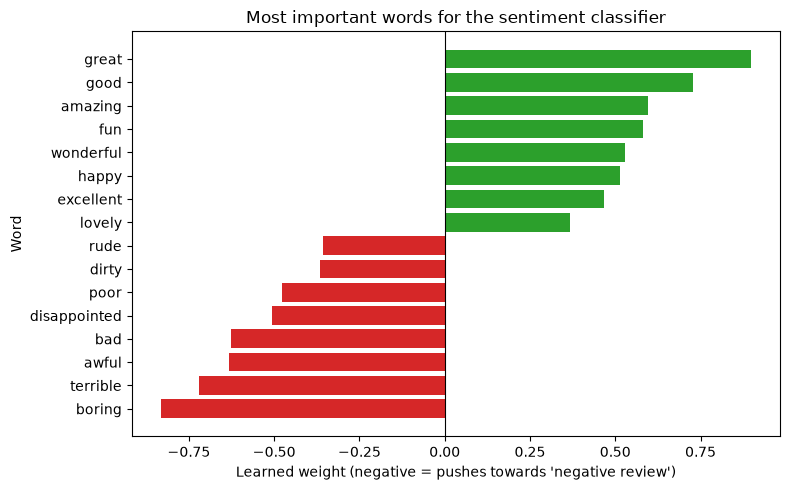

In [15]:
model.fit(texts, labels)                            # final model: train on all 40 reviews
vec = model.named_steps["tfidfvectorizer"]          # grab the TF-IDF step out of the pipeline
clf = model.named_steps["logisticregression"]       # grab the classifier step

weights = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())  # one learned weight per word
top = pd.concat([weights.nsmallest(8), weights.nlargest(8).iloc[::-1]])  # 8 most negative + 8 most positive

plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color=["tab:red" if w < 0 else "tab:green" for w in top.values])
plt.axvline(0, color="black", linewidth=0.8)        # the zero line
plt.title("Most important words for the sentiment classifier")
plt.xlabel("Learned weight (negative = pushes towards 'negative review')")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

**What just happened?**

Logistic regression learns one **weight** per word. Green bars push a review towards *positive*, red bars towards *negative*. The model has discovered sentiment words like *great*, *good*, *bad* and *boring* on its own, just from the labels. This is one of the nicest things about simple models: you can read their reasoning.

Now let's try to **break** it with sentences it has never seen, including **negation** ("not good").

In [16]:
tricky = [
    "The movie was good",
    "The movie was not good",
    "The movie was bad",
    "The movie was not bad at all",
    "I would not recommend this phone",
]
probs = model.predict_proba(tricky)[:, 1]           # probability of the "positive" class
print("Is 'not' in the vocabulary?", "not" in vec.vocabulary_)
pd.DataFrame({"sentence": tricky, "P(positive)": probs.round(2),
              "prediction": np.where(probs >= 0.5, "positive", "negative")})

Is 'not' in the vocabulary? False


,sentence,P(positive),prediction
0,The movie was good,0.59,positive
1,The movie was not good,0.59,positive
2,The movie was bad,0.41,negative
3,The movie was not bad at all,0.41,negative
4,I would not recommend this phone,0.50,negative


**What just happened?**

Look at the table:
- "The movie was good" and "The movie was **not** good" get **exactly the same** probability. The same is true for "bad" vs "not bad at all".
- The reason is printed above the table: `"not"` is **not in the vocabulary** (none of our 40 training reviews contain it), so the vectorizer silently drops it. Even if it were in the vocabulary, bag of words would only see `not` + `good` as two separate words in a bag, not "not good" as a phrase.
- "I would not recommend this phone" lands at about 0.50, a coin flip: apart from *phone* (which leans positive in our data) and a few filler words, the model knows none of its words, so the prediction is basically luck.

> 💡 **Tip:** common fixes are (1) more training data that *contains* negations, and (2) counting pairs of neighbouring words too, called **bigrams** (`TfidfVectorizer(ngram_range=(1, 2))` would add a `not good` column). Modern models instead read words *in context*, which leads us to embeddings.

## 8. Embeddings: meaning as a position

An **embedding** is a list of numbers (a vector) produced by a neural network that has been trained on huge amounts of text so that **texts with similar meaning get similar vectors**. You can think of it as GPS coordinates for meaning:

```
    "A dog is playing"   •  • "A puppy runs on the grass"        (close together: same meaning)


                                         • "Share prices dropped"   (far away: different topic)
```

Unlike TF-IDF, embeddings are **dense** (every number is used, no big blocks of zeros) and have a fixed length no matter how big the vocabulary is.

We use **all-MiniLM-L6-v2**, a small, popular sentence-embedding model (about 23 million parameters, loaded from the local cache).

In [17]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")  # local, CPU

sentences = [
    "A dog is playing in the park",
    "A puppy runs around on the grass",
    "The stock market fell sharply today",
    "Share prices dropped this morning",
    "I am baking a chocolate cake",
    "She is making a dessert in the kitchen",
]
emb = embedder.encode(sentences, normalize_embeddings=True)   # one vector per sentence
print("Embeddings shape:", emb.shape)               # (number of sentences, numbers per sentence)
print("First 5 numbers of sentence 0:", emb[0][:5].round(3))

Embeddings shape: (6, 384)
First 5 numbers of sentence 0: [ 0.055 -0.073  0.068 -0.013  0.029]


**What just happened?**

Each sentence became a vector of **384** numbers, whatever its length. Individual numbers (like the first five printed above) are not meaningful to humans; only the *relationships* between vectors are. `normalize_embeddings=True` scales each vector to length 1, which makes cosine similarity easy to compute.

Let's compare similarities from TF-IDF and from embeddings side by side as **heatmaps** (colour-coded tables).

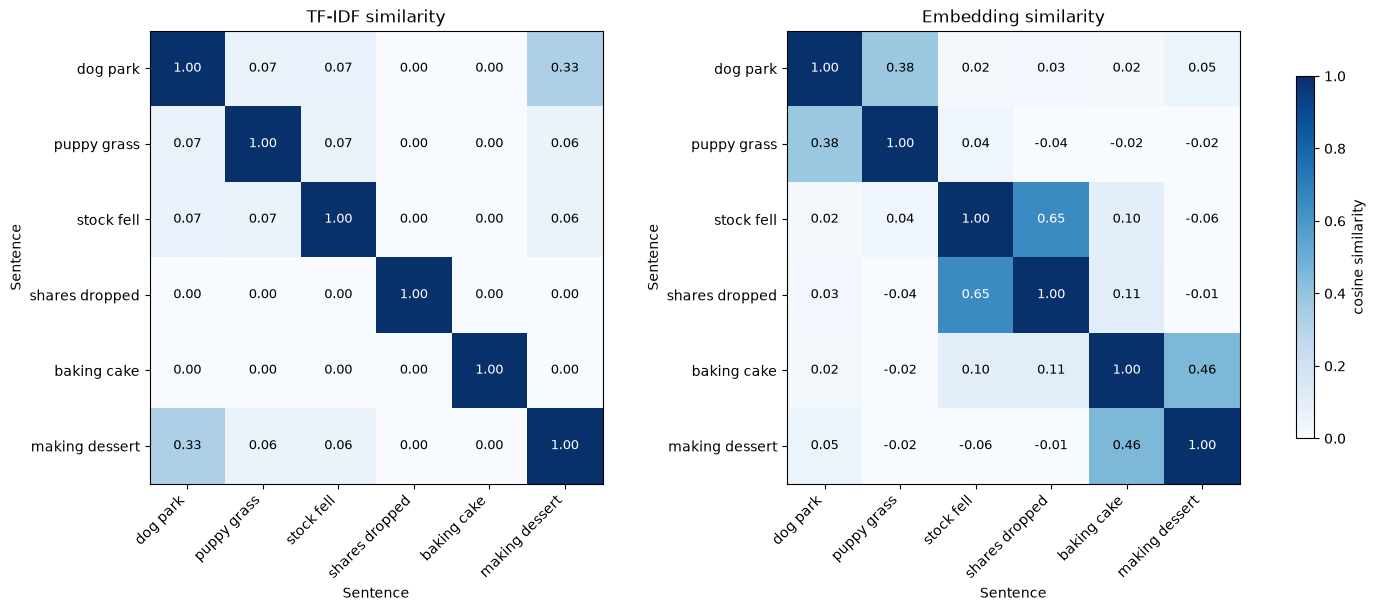

In [18]:
tfidf_sim = cosine_similarity(TfidfVectorizer().fit_transform(sentences))  # word-overlap similarity
emb_sim = cosine_similarity(emb)                                         # meaning similarity

short = ["dog park", "puppy grass", "stock fell", "shares dropped", "baking cake", "making dessert"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)  # 2 side-by-side plots
for ax, mat, title in zip(axes, [tfidf_sim, emb_sim], ["TF-IDF similarity", "Embedding similarity"]):
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="Blues")         # colour each cell by its value
    ax.set_xticks(range(6)); ax.set_xticklabels(short, rotation=45, ha="right")
    ax.set_yticks(range(6)); ax.set_yticklabels(short)
    for i in range(6):
        for j in range(6):                                    # write the number in each cell
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                    color="white" if mat[i, j] > 0.6 else "black", fontsize=9)
    ax.set_title(title); ax.set_xlabel("Sentence"); ax.set_ylabel("Sentence")
fig.colorbar(im, ax=axes, shrink=0.8, label="cosine similarity")
plt.show()

**What just happened?**

- **Left (TF-IDF):** the pairs that mean the same thing ("stock fell" / "shares dropped", "baking cake" / "making dessert") score **0.00**, because they share no words. Worse, the *highest* score off the diagonal (0.33) is "dog park" vs "making dessert", two unrelated sentences that just happen to share the filler words *is*, *in*, *the*.
- **Right (embeddings):** the three meaning pairs light up: dog/puppy about 0.38, stock/shares about 0.65, cake/dessert about 0.46, while sentences from different topics stay near 0 (at most about 0.11).

This is the big leap: embeddings capture **meaning**, not spelling. (Embedding similarities can even be slightly negative; the colour scale simply clips those at 0.)

### A mini semantic search engine

**Semantic search** means finding texts by meaning instead of exact keywords. Recipe:
1. embed all documents once,
2. embed the user's question,
3. return the documents with the highest cosine similarity.

This is exactly the "retrieval" step inside **RAG** (Retrieval-Augmented Generation) systems that you will meet in the LLM section.

In [19]:
docs = [
    # pets
    "My cat sleeps on the windowsill all afternoon", "Dogs need a walk at least twice a day",
    "The vet said our rabbit is perfectly healthy", "Goldfish are easy pets for small apartments",
    "Our puppy chewed through my favourite shoes",
    # food
    "Add garlic and onions to the pan before the tomatoes", "This soup recipe takes only twenty minutes",
    "Fresh bread tastes best straight from the oven", "Spicy noodles are my favourite late night meal",
    "Let the pasta water boil before adding salt",
    # technology
    "Restart the router if the wifi keeps disconnecting", "My laptop battery drains much faster than before",
    "Update your phone to get the latest security fixes", "The printer is jammed again",
    "Back up your files to an external drive every week",
]
topics = ["pets"] * 5 + ["food"] * 5 + ["technology"] * 5
doc_emb = embedder.encode(docs, normalize_embeddings=True)    # step 1: embed every document once

def search(query, k=3):
    q = embedder.encode([query], normalize_embeddings=True)   # step 2: embed the question
    scores = cosine_similarity(q, doc_emb)[0]                 # step 3: compare with every document
    best = np.argsort(-scores)[:k]                            # indices of the k highest scores
    return [(round(float(scores[i]), 2), docs[i]) for i in best]

for query in ["my computer will not charge properly", "what can I cook quickly for dinner",
              "my kitten keeps napping in the sun"]:
    print("QUERY:", query)
    for score, doc in search(query):
        print(f"   {score:.2f}  {doc}")

QUERY: my computer will not charge properly
   0.46  My laptop battery drains much faster than before
   0.26  Update your phone to get the latest security fixes
   0.23  The printer is jammed again
QUERY: what can I cook quickly for dinner
   0.44  This soup recipe takes only twenty minutes
   0.44  Spicy noodles are my favourite late night meal
   0.41  Add garlic and onions to the pan before the tomatoes
QUERY: my kitten keeps napping in the sun


   0.58  My cat sleeps on the windowsill all afternoon
   0.27  Our puppy chewed through my favourite shoes
   0.23  Dogs need a walk at least twice a day


**What just happened?**

For each query the three closest documents are printed with their similarity scores:
- "my computer will not charge properly" → "My **laptop battery** drains..." (about 0.46), well ahead of the next result. The two sentences share no important word: *computer*/*laptop* and *charge*/*battery* are matched by meaning.
- "my kitten keeps napping in the sun" → "My **cat sleeps** on the windowsill..." (about 0.58). Again *kitten*/*cat* and *napping*/*sleeps* are different words.
- "what can I cook quickly for dinner" → all three results are food sentences, with the quick soup recipe and the noodles tied at the top (about 0.44). Food sentences share the topic, so the scores are close together.

A plain keyword search would have found nothing useful for the first two queries.

### A 2-D map of meaning

Our embeddings have 384 numbers each, and we cannot draw 384 dimensions. **PCA** (Principal Component Analysis) squashes them down to 2 numbers while keeping as much of the spread as possible, so we can plot each sentence as a dot.

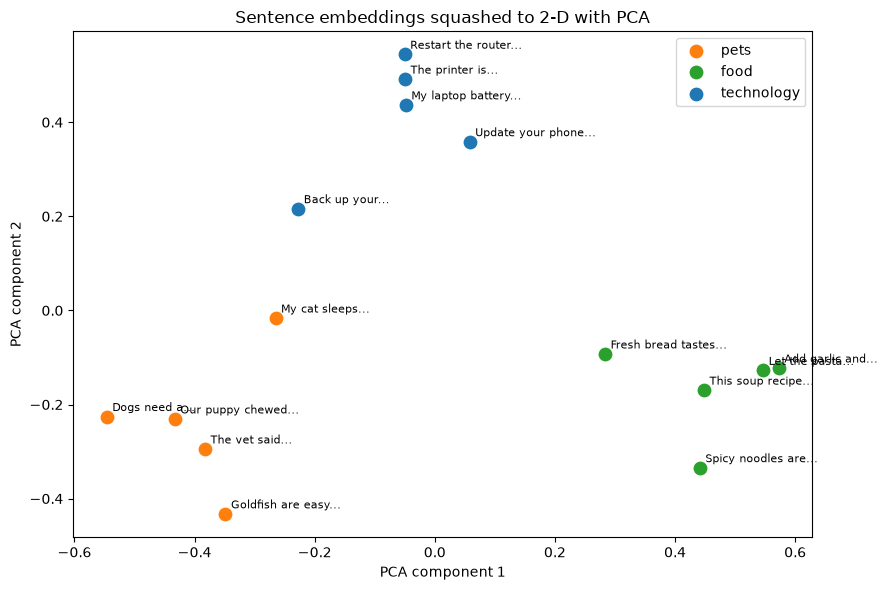

In [20]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=SEED).fit_transform(doc_emb)   # 384 numbers -> 2 numbers

plt.figure(figsize=(9, 6))
for topic, color in zip(["pets", "food", "technology"], ["tab:orange", "tab:green", "tab:blue"]):
    idx = [i for i, t in enumerate(topics) if t == topic]           # dots for this topic
    plt.scatter(xy[idx, 0], xy[idx, 1], s=80, color=color, label=topic)
    for i in idx:                                                    # label each dot with its first words
        plt.annotate(" ".join(docs[i].split()[:3]) + "...", xy[i], fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
plt.title("Sentence embeddings squashed to 2-D with PCA")
plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2")
plt.legend(); plt.tight_layout(); plt.show()

**What just happened?**

Each dot is one sentence, coloured by the topic *we* assigned (the model never saw these labels). Here the three topics form three clearly separate groups: technology at the top, food on the right, pets on the left. The embedding model placed similar meanings close together on its own. With harder or overlapping topics you would see more mixing, because squashing 384 numbers into 2 throws information away.

### Do embeddings understand "not good"?

Our word-counting classifier could not see the difference between "good" and "not good". Embedding models read the whole sentence at once, so they *might* do better. Let's test it honestly in two ways:
1. compare similarities directly,
2. train the same logistic regression on embeddings instead of TF-IDF and re-run the tricky sentences.

In [21]:
base = "The movie was good"
others = ["The movie was great", "The movie was not good", "The movie was bad", "The weather is sunny"]
e_base = embedder.encode([base], normalize_embeddings=True)          # embed the reference sentence
e_oth = embedder.encode(others, normalize_embeddings=True)           # embed the comparison sentences
print(f"Similarity to: {base!r}")
for s, score in zip(others, cosine_similarity(e_base, e_oth)[0]):
    print(f"   {score:.2f}  {s}")

Similarity to: 'The movie was good'
   0.91  The movie was great
   0.82  The movie was not good
   0.79  The movie was bad
   0.04  The weather is sunny


**What just happened?**

- "The movie was great" is the closest (about 0.91): a synonym, as hoped.
- But "The movie was **not good**" (about 0.82) is *more* similar to "good" than "The movie was bad" is (about 0.79), and almost as similar as "great". The embedding mostly sees "a sentence about a movie being good-ish", so the opposite meaning is only a small nudge.
- The unrelated weather sentence is near 0, so the model clearly understands *topic*.

So, measured by similarity alone, this small embedding model does **not** cleanly separate "good" from "not good".

In [22]:
emb_clf = LogisticRegression(max_iter=1000)                          # same classifier type as before
emb_clf.fit(embedder.encode(texts, normalize_embeddings=True), labels)  # ...trained on embeddings

p_emb = emb_clf.predict_proba(embedder.encode(tricky, normalize_embeddings=True))[:, 1]
pd.DataFrame({"sentence": tricky,
              "TF-IDF P(positive)": probs.round(2),                  # from the earlier model
              "Embedding P(positive)": p_emb.round(2)})

,sentence,TF-IDF P(positive),Embedding P(positive)
0,The movie was good,0.59,0.57
1,The movie was not good,0.59,0.30
2,The movie was bad,0.41,0.25
3,The movie was not bad at all,0.41,0.33
4,I would not recommend this phone,0.50,0.55


**What just happened?**

Same classifier, same 40 reviews, only the numbers changed (embeddings instead of TF-IDF). In this run:
- "The movie was **not good**" now gets about 0.30, i.e. *negative*, while "good" gets about 0.57. That is a real improvement: the embedding carries some of the "not".
- "The movie was **not bad at all**" still comes out negative (about 0.33), which is wrong.
- "I would **not** recommend this phone" comes out slightly positive (about 0.55), also wrong.

So embeddings help with some negations and not others. Notice also that the embedding-based probabilities are a bit more confident overall (further from 0.5) than the TF-IDF ones.

**Honest summary:** embeddings are a big step up from counting words (synonyms, paraphrases, topics), but they are not magic. Negation, sarcasm and subtle logic are still hard for small models, which is one reason much larger language models exist.

## Recap

- Models only understand **numbers**, so every NLP system starts by converting text into numbers.
- **Cleaning** (lowercasing, removing punctuation) merges spellings but can destroy meaning (`US` vs `us`, smileys).
- **Tokenization** splits text into tokens. Word-level vocabularies have *unknown words*; **subword** tokenizers (used by LLMs) can represent any text, splitting rare words into pieces.
- **Bag of words** counts words; **TF-IDF** weights them by how distinctive they are. Both ignore word order and only match exact spellings.
- **Cosine similarity** measures how closely two vectors point in the same direction (1 = same, 0 = unrelated).
- A **TF-IDF + logistic regression** classifier is fast, readable (you can see its important words) and a great baseline, but it fails on negation and unseen words.
- **Embeddings** place texts with similar meaning close together, enabling **semantic search** and meaningful 2-D maps. They handle synonyms well, but negation is still not fully solved.

## Exercises

**1. (Easy)** Use the Qwen tokenizer (`tok`) to count the tokens in your own name and in the word `"supercalifragilisticexpialidocious"`. Which pieces does it use?

<details><summary>Show solution</summary>

```python
for w in ["Oluwaseun", "supercalifragilisticexpialidocious"]:
    ids = tok.encode(w)
    print(w, len(ids), [tok.decode([i]) for i in ids])
```
Rare words and names are split into several common pieces.
</details>

**2. (Easy)** Add the sentence `"cats are friendly and so are dogs"` to `corpus`, re-run TF-IDF and cosine similarity. Which old sentence is now most similar to `doc2`?

<details><summary>Show solution</summary>

```python
corpus2 = corpus + ["cats are friendly and so are dogs"]
X2 = TfidfVectorizer().fit_transform(corpus2)
print(cosine_similarity(X2).round(2))
```
`doc2` ("cats and dogs are friends") now shares `cats`, `and`, `dogs`, `are` with the new sentence, so their similarity is clearly above 0.
</details>

**3. (Medium)** Retrain the sentiment model with bigrams and a few negated training examples. Does "The movie was not good" change?

<details><summary>Show solution</summary>

```python
extra_texts = ["It was not good at all", "Not good, would not buy again",
               "Not bad, I enjoyed it", "It was not bad, quite fun actually"]
extra_labels = [0, 0, 1, 1]
m2 = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression())
m2.fit(texts + extra_texts, labels + extra_labels)
print(m2.predict_proba(tricky)[:, 1].round(2))
```
Now `not good` and `not bad` exist as bigram columns, so "not good" can finally get a *different* score from "good". When we tried it, "not good" dropped to just under 0.5 (negative), but "not bad at all" stayed on the negative side: four extra examples are not enough to outweigh the strong word *bad*. Real systems need many examples of each pattern.
</details>

**4. (Medium)** Add three sentences about **sports** to `docs` (with topic `"sports"`), re-embed and re-draw the PCA plot. Do they form their own cluster?

<details><summary>Show solution</summary>

```python
docs2 = docs + ["The striker scored twice in the final", "She runs five kilometres every morning",
                "The tennis match went to a fifth set"]
topics2 = topics + ["sports"] * 3
xy2 = PCA(n_components=2).fit_transform(embedder.encode(docs2, normalize_embeddings=True))
for t in set(topics2):
    idx = [i for i, x in enumerate(topics2) if x == t]
    plt.scatter(xy2[idx, 0], xy2[idx, 1], label=t)
plt.legend(); plt.title("With sports"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()
```
</details>

**5. (Harder)** Build a semantic search that returns *nothing* if the best score is below a threshold (e.g. 0.3). Test it with an off-topic query such as `"how tall is Mount Everest"`.

<details><summary>Show solution</summary>

```python
def search_with_threshold(query, k=3, threshold=0.3):
    results = [(s, d) for s, d in search(query, k) if s >= threshold]
    return results or "No good match found."
print(search_with_threshold("how tall is Mount Everest"))
```
Real search systems use a threshold like this to say "I don't know" instead of returning a bad match. The right threshold depends on the model and data, so test a few values.
</details>

## Where to go next

Next in NLP (this folder):
- [01_text_preprocessing.ipynb](01_text_preprocessing.ipynb): cleaning, stemming, lemmatization and more tokenizers in depth
- [02_word_embeddings.ipynb](02_word_embeddings.ipynb): how word embeddings (Word2Vec, GloVe-style) are learned
- [03_text_classification.ipynb](03_text_classification.ipynb): stronger text classifiers
- [09_sentence_embeddings_advanced.ipynb](09_sentence_embeddings_advanced.ipynb): more on sentence embeddings
- [13_industry_semantic_search_engine.ipynb](13_industry_semantic_search_engine.ipynb): a full semantic search engine
- Notes: [notes/07_NLP.md](notes/07_NLP.md)

Then see how large language models use tokens to *generate* text:
- [../08_LLM/00_start_here_how_llms_work.ipynb](../08_LLM/00_start_here_how_llms_work.ipynb)